# Original course analysis

This notebook preserves the original course code and saved outputs. Runtime widget metadata has been removed. Drive paths and intermediate exploration are original. See the project README and analysis.py for the separate portfolio edition and independently regenerated results.


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd

file_path = "/content/drive/MyDrive/Colab Notebooks/PlayStore_Permissions_Joined.csv"

df = pd.read_csv(file_path)

In [4]:
df.head()

,App Name,App Id,Category,Rating,Rating Count,Installs,Minimum Installs,Maximum Installs,Free,Price,...,num_permission_types,perm_Camera,perm_Location,perm_Microphone,perm_Contacts,perm_SMS,perm_Phone,perm_Storage,perm_Photos,perm_Calendar
0,Gakondo,com.ishakwe.gakondo,Adventure,0.0,0.0,10+,10.0,15,True,0.0,...,2,True,False,False,False,False,False,False,False,False
1,Ampere Battery Info,com.webserveis.batteryinfo,Tools,4.4,64.0,"5,000+",5000.0,7662,True,0.0,...,1,False,False,False,False,False,False,False,False,False
2,Vibook,com.doantiepvien.crm,Productivity,0.0,0.0,50+,50.0,58,True,0.0,...,5,True,False,False,False,False,True,True,True,False
3,Smart City Trichy Public Service Vehicles 17UC...,cst.stJoseph.ug17ucs548,Communication,5.0,5.0,10+,10.0,19,True,0.0,...,1,False,False,False,False,False,False,False,False,False
4,GROW.me,com.horodyski.grower,Tools,0.0,0.0,100+,100.0,478,True,0.0,...,10,True,True,True,True,False,True,True,True,False


In [6]:
print("Column types:")
print(df.dtypes)

missing = df.isna().sum().to_frame("missing")
missing["pct_missing"] = (missing["missing"] / len(df) * 100).round(2)
print("\nColumns with missing values:")
display(missing[missing["missing"] > 0].sort_values("missing", ascending=False))

print("Duplicate App Ids:", df["App Id"].duplicated().sum())

Column types:
App Name                 object
App Id                   object
Category                 object
Rating                  float64
Rating Count            float64
Installs                 object
Minimum Installs        float64
Maximum Installs          int64
Free                       bool
Price                   float64
Currency                 object
Size                     object
Minimum Android          object
Developer Id             object
Developer Website        object
Developer Email          object
Released                 object
Last Updated             object
Content Rating           object
Privacy Policy           object
Ad Supported               bool
In App Purchases           bool
Editors Choice             bool
Scraped Time             object
permission_count          int64
permission_types         object
num_permission_types      int64
perm_Camera                bool
perm_Location              bool
perm_Microphone            bool
perm_Contacts             

,missing,pct_missing
Developer Website,760835,32.89
Privacy Policy,420953,18.20
permission_types,93113,4.03
Released,71053,3.07
Rating,22883,0.99
Rating Count,22883,0.99
Minimum Android,6530,0.28
Size,196,0.01
Currency,135,0.01
Installs,107,0.00


Duplicate App Ids: 0


In [7]:
SCRAPE_DATE = pd.to_datetime(df["Scraped Time"], errors="coerce").max().normalize()
print("Data was scraped on:", SCRAPE_DATE.date())

pp = df["Privacy Policy"]
df["has_privacy_policy"] = pp.notna() & (pp.astype(str).str.strip() != "")

cols_to_drop = ["Developer Website", "Developer Email", "Privacy Policy", "Scraped Time", "Installs"]
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
print(f"Now {df.shape[1]} columns")

Data was scraped on: 2021-06-16
Now 32 columns


In [8]:
import numpy as np

# True/False columns
def to_bool(series):
    return series.astype(str).str.strip().str.lower().eq("true")

for col in ["Free", "Ad Supported", "In App Purchases", "Editors Choice"]:
    df[col] = to_bool(df[col])

# Numeric columns
num_cols = ["Rating", "Rating Count", "Minimum Installs", "Maximum Installs",
            "Price", "permission_count", "num_permission_types"]
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Price"] = df["Price"].fillna(0)
df["Rating Count"] = df["Rating Count"].fillna(0)

# Unrated apps show 0.0; treat these as "no rating" instead of a real score
df.loc[df["Rating Count"] == 0, "Rating"] = np.nan
df.loc[(df["Rating"] < 1) | (df["Rating"] > 5), "Rating"] = np.nan

# Size: "10M" / "512k" / "1.2G" / "Varies with device" -> megabytes
size_text = df["Size"].astype(str).str.replace(",", "", regex=False).str.strip()
size_num = pd.to_numeric(size_text.str.extract(r"^([\d.]+)")[0], errors="coerce")
size_unit = size_text.str.extract(r"([kKmMgG])$|")[0].str.upper()
df["size_mb"] = size_num * size_unit.map({"K": 1 / 1024, "M": 1, "G": 1024})
df["size_varies"] = size_text.str.contains("Varies", case=False, na=False)

# Minimum Android: "4.1 and up" -> 4.1
df["min_android_version"] = pd.to_numeric(
    df["Minimum Android"].astype(str).str.extract(r"^(\d+(?:\.\d+)?)")[0], errors="coerce")

# Dates
for col in ["Released", "Last Updated"]:
    df[col] = pd.to_datetime(df[col], format="%b %d, %Y", errors="coerce")

# Free should always match Price
df["Free"] = df["Price"] == 0

df = df.drop(columns=["Size", "Minimum Android"])
print(df.dtypes)

App Name                        object
App Id                          object
Category                        object
Rating                         float64
Rating Count                   float64
Minimum Installs               float64
Maximum Installs                 int64
Free                              bool
Price                          float64
Currency                        object
Developer Id                    object
Released                datetime64[ns]
Last Updated            datetime64[ns]
Content Rating                  object
Ad Supported                      bool
In App Purchases                  bool
Editors Choice                    bool
permission_count                 int64
permission_types                object
num_permission_types             int64
perm_Camera                       bool
perm_Location                     bool
perm_Microphone                   bool
perm_Contacts                     bool
perm_SMS                          bool
perm_Phone               

In [9]:
def log_step(msg, old_len):
    global df
    new_len = len(df)
    diff = old_len - new_len
    if diff > 0:
        print(f"{msg}: {new_len:,} apps ({diff:,} removed)")
    else:
        print(f"{msg}: {new_len:,} apps")

n = len(df)
df = df.drop_duplicates(subset="App Id", keep="first")
log_step("Removed duplicate App Ids", n)

n = len(df)
df = df.dropna(subset=["App Name", "Category"])
log_step("Removed apps missing name or category", n)

n = len(df)
df = df.dropna(subset=["Minimum Installs"])
log_step("Removed apps missing install data", n)

if "Currency" in df.columns:
    n = len(df)
    df = df[~((df["Price"] > 0) & (df["Currency"] != "USD"))]
    log_step("Removed paid apps priced in non-USD currency", n)
    df = df.drop(columns=["Currency"])

Removed duplicate App Ids: 2,312,944 apps
Removed apps missing name or category: 2,312,939 apps (5 removed)
Removed apps missing install data: 2,312,832 apps (107 removed)
Removed paid apps priced in non-USD currency: 2,312,832 apps


In [10]:
df["Category"] = df["Category"].astype(str).str.strip()

GAME_GENRES = {
    "Action", "Adventure", "Arcade", "Board", "Card", "Casino", "Casual",
    "Educational", "Music", "Puzzle", "Racing", "Role Playing", "Simulation",
    "Strategy", "Trivia", "Word",
}
df["is_game"] = df["Category"].isin(GAME_GENRES)
df["category_group"] = np.where(df["is_game"], "Game", "App")

print(df["category_group"].value_counts(), "\n")
print(df["Category"].value_counts().to_string())

category_group
App     1984402
Game     328430
Name: count, dtype: int64 

Category
Education                  241090
Music & Audio              154906
Tools                      143985
Business                   143771
Entertainment              138273
Lifestyle                  118331
Books & Reference          116728
Personalization             89209
Health & Fitness            83509
Productivity                79698
Shopping                    75253
Food & Drink                73926
Travel & Local              67287
Finance                     65464
Arcade                      53787
Puzzle                      51160
Casual                      50809
Communication               48167
Sports                      47479
Social                      44730
News & Magazines            42806
Photography                 35552
Medical                     32065
Action                      27546
Maps & Navigation           26722
Simulation                  23272
Adventure                   2319

In [11]:
df["permission_types"] = df["permission_types"].fillna("").astype(str).str.strip()

# 1) See every permission type in the data
all_perm_types = (df.loc[df["permission_types"] != "", "permission_types"]
                    .str.split(";").explode().str.strip())
all_perm_types = all_perm_types[all_perm_types != ""].value_counts()
print("Permission types found (number of apps using each):")
print(all_perm_types.to_string(), "\n")

# 2) Sensitive permission groups
SENSITIVE_GROUPS = {
    "perm_location":     "Location",
    "perm_camera":       "Camera",
    "perm_microphone":   "Microphone",
    "perm_contacts":     "Contacts",
    "perm_phone":        "Phone",
    "perm_sms":          "SMS",
    "perm_calendar":     "Calendar",
    "perm_identity":     "Identity",
    "perm_device_id":    "Device ID & call information",
    "perm_media_files":  "Photos/Media/Files",
    "perm_storage":      "Storage",
    "perm_body_sensors": "Wearable sensors/Activity data",
    "perm_app_history":  "Device & app history",
}
for name in SENSITIVE_GROUPS.values():
    if name not in all_perm_types.index:
        print(f"WARNING: '{name}' not found in the data. Check the list above for the exact spelling.")

# 3) One True/False column per group (exact match on the "; "-separated list)
padded = "; " + df["permission_types"] + ";"
for col, name in SENSITIVE_GROUPS.items():
    df[col] = padded.str.contains("; " + name + ";", regex=False)

# 4) Count and tier
perm_cols = list(SENSITIVE_GROUPS.keys())
df["sensitive_permission_count"] = df[perm_cols].sum(axis=1).astype(int)
df["privacy_tier"] = pd.cut(df["sensitive_permission_count"],
                            bins=[-1, 0, 2, np.inf],
                            labels=["Minimal", "Moderate", "Heavy"])

# 5) Flag apps with no permission records
df["permission_count"] = df["permission_count"].fillna(0).astype(int)
df["num_permission_types"] = df["num_permission_types"].fillna(0).astype(int)
df["has_permission_data"] = df["permission_count"] > 0

print(df["privacy_tier"].value_counts())

Permission types found (number of apps using each):
permission_types
Other                             2204289
Photos/Media/Files                1383818
Storage                           1383689
Wi-Fi connection information       829995
Location                           678225
Camera                             547372
Phone                              500444
Device ID & call information       426922
Contacts                           285590
Microphone                         248798
Identity                           194523
Device & app history                99266
Calendar                            91997
SMS                                  2971
Wearable sensors/Activity data       1959
Cellular data settings                639 

privacy_tier
Heavy       973825
Minimal     723823
Moderate    615184
Name: count, dtype: int64


In [12]:
conditions = [
    df["Price"] > 0,
    df["Ad Supported"] & df["In App Purchases"],
    ~df["Ad Supported"] & df["In App Purchases"],
    df["Ad Supported"] & ~df["In App Purchases"],
]
labels = ["Paid", "Freemium (Ads + IAP)", "Freemium (IAP only)", "Ad-supported"]
df["monetization_model"] = np.select(conditions, labels, default="Free (no monetization)")

df["price_outlier"] = df["Price"] > 100

print(df["monetization_model"].value_counts())
print("\nApps priced over $100:", int(df["price_outlier"].sum()))

monetization_model
Free (no monetization)    1068560
Ad-supported              1007063
Freemium (Ads + IAP)       141060
Freemium (IAP only)         51216
Paid                        44933
Name: count, dtype: int64

Apps priced over $100: 184


In [13]:
SUCCESS_MIN_INSTALLS = 100_000
SUCCESS_MIN_RATING = 4.0

df["days_since_update"] = (SCRAPE_DATE - df["Last Updated"]).dt.days
df["is_active"] = df["days_since_update"] <= 365
df["app_age_years"] = ((SCRAPE_DATE - df["Released"]).dt.days / 365.25).round(1)

df["install_tier"] = pd.cut(
    df["Minimum Installs"],
    bins=[-1, 999, 9_999, 99_999, 999_999, 9_999_999, np.inf],
    labels=["<1K", "1K-10K", "10K-100K", "100K-1M", "1M-10M", "10M+"],
)

df["is_rated"] = df["Rating Count"] >= 10
df["is_successful"] = (df["Minimum Installs"] >= SUCCESS_MIN_INSTALLS) & (df["Rating"] >= SUCCESS_MIN_RATING)

print("Active apps:     ", f"{df['is_active'].mean():.1%}")
print("Rated (10+):     ", f"{df['is_rated'].mean():.1%}")
print("Successful apps: ", f"{int(df['is_successful'].sum()):,}")
print(df["install_tier"].value_counts().sort_index())

Active apps:      47.4%
Rated (10+):      42.7%
Successful apps:  113,788
install_tier
<1K         1253746
1K-10K       541791
10K-100K     332081
100K-1M      137269
1M-10M        40245
10M+           7700
Name: count, dtype: int64


In [14]:
df.columns = (df.columns.str.strip().str.lower()
                .str.replace(" ", "_", regex=False))

for col in ["category", "category_group", "monetization_model", "content_rating"]:
    if col in df.columns:
        df[col] = df[col].astype("category")

df["rating_count"] = df["rating_count"].astype("int64")
df["minimum_installs"] = df["minimum_installs"].astype("int64")

front = ["app_id", "app_name", "developer_id", "category", "category_group", "is_game",
         "rating", "rating_count", "is_rated", "minimum_installs", "maximum_installs", "install_tier",
         "price", "free", "ad_supported", "in_app_purchases", "monetization_model", "price_outlier",
         "privacy_tier", "sensitive_permission_count", "permission_count", "num_permission_types",
         "has_permission_data", "has_privacy_policy"]
front = [c for c in front if c in df.columns]
df = df[front + [c for c in df.columns if c not in front]]

print(f"{len(df):,} rows x {df.shape[1]} columns")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

2,312,832 rows x 74 columns
Memory: 1.14 GB


In [15]:
df.head(50)

,app_id,app_name,developer_id,category,category_group,is_game,rating,rating_count,is_rated,minimum_installs,...,perm_device_id,perm_media_files,perm_storage,perm_storage,perm_body_sensors,perm_app_history,days_since_update,is_active,app_age_years,is_successful
0,com.ishakwe.gakondo,Gakondo,Jean Confident Irénée NIYIZIBYOSE,Adventure,Game,True,NaN,0,False,10,...,False,False,False,False,False,False,476,False,1.3,False
1,com.webserveis.batteryinfo,Ampere Battery Info,Webserveis,Tools,App,False,4.4,64,True,5000,...,False,False,False,False,False,False,41,True,1.1,False
2,com.doantiepvien.crm,Vibook,Cabin Crew,Productivity,App,False,NaN,0,False,50,...,False,True,True,True,False,False,667,False,1.9,False
3,cst.stJoseph.ug17ucs548,Smart City Trichy Public Service Vehicles 17UC...,Climate Smart Tech2,Communication,App,False,5.0,5,False,10,...,False,False,False,False,False,False,977,False,2.8,False
4,com.horodyski.grower,GROW.me,Rafal Milek-Horodyski,Tools,App,False,NaN,0,False,100,...,True,True,True,True,False,False,947,False,1.3,False
5,com.imocci,IMOCCI,Imocci GmbH,Social,App,False,NaN,0,False,50,...,False,True,True,True,False,False,544,False,2.5,False
6,getfreedata.superfatiza.unlimitedjiodataprank,unlimited 4G data prank free app,android developer779,Libraries & Demo,App,False,4.5,12,True,1000,...,False,False,False,False,False,False,628,False,1.7,False
7,com.mozaix.simoneboard,The Everyday Calendar,Mozaix LLC,Lifestyle,App,False,2.0,39,True,500,...,True,True,True,True,False,False,726,False,2.0,False
8,com.whatsopen.app,WhatsOpen,Yilver Molina Hurtatiz,Communication,App,False,NaN,0,False,10,...,False,False,False,False,False,False,922,False,NaN,False
9,com.ikeyboard.theme.neon_3d.iron.tech,Neon 3d Iron Tech Keyboard Theme,Free 2021 Themes for Emoji keyboard,Personalization,App,False,4.7,820,True,50000,...,False,True,True,True,False,False,252,True,1.7,False


In [16]:
display(df.columns)

Index(['app_id', 'app_name', 'developer_id', 'category', 'category_group',
       'is_game', 'rating', 'rating_count', 'is_rated', 'minimum_installs',
       'maximum_installs', 'install_tier', 'price', 'free', 'ad_supported',
       'in_app_purchases', 'monetization_model', 'price_outlier',
       'privacy_tier', 'sensitive_permission_count', 'permission_count',
       'num_permission_types', 'has_permission_data', 'has_privacy_policy',
       'released', 'last_updated', 'content_rating', 'editors_choice',
       'permission_types', 'perm_camera', 'perm_camera', 'perm_location',
       'perm_location', 'perm_microphone', 'perm_microphone', 'perm_contacts',
       'perm_contacts', 'perm_sms', 'perm_sms', 'perm_phone', 'perm_phone',
       'perm_storage', 'perm_storage', 'perm_photos', 'perm_calendar',
       'perm_calendar', 'size_mb', 'size_varies', 'min_android_version',
       'perm_location', 'perm_location', 'perm_camera', 'perm_camera',
       'perm_microphone', 'perm_microphone'

In [17]:
df.to_csv(
    "/content/drive/MyDrive/Colab Notebooks/Andrew_Clean_Dataset.csv",
    index=False
)

print("Andrew's cleaned dataset saved successfully!")

Andrew's cleaned dataset saved successfully!


In [18]:
import os

file_path = "/content/drive/MyDrive/Colab Notebooks/Andrew_Clean_Dataset.csv"

print("File exists:", os.path.exists(file_path))
print(f"File size: {os.path.getsize(file_path) / (1024**3):.2f} GB")

File exists: True
File size: 1.12 GB


In [19]:
# Basic dataset information
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Variables likely relevant to our analysis
important_columns = [
    'category',
    'rating',
    'rating_count',
    'minimum_installs',
    'maximum_installs',
    'install_tier',
    'privacy_tier',
    'sensitive_permission_count',
    'permission_count',
    'num_permission_types',
    'has_permission_data',
    'has_privacy_policy',
    'is_successful'
]

print("\nImportant columns:")
for col in important_columns:
    if col in df.columns:
        print(f"{col}: {df[col].dtype}")
    else:
        print(f"{col}: NOT FOUND")

Rows: 2312832
Columns: 74

Important columns:
category: category
rating: float64
rating_count: int64
minimum_installs: int64
maximum_installs: int64
install_tier: category
privacy_tier: category
sensitive_permission_count: int64
permission_count: int64
num_permission_types: int64
has_permission_data: bool
has_privacy_policy: bool
is_successful: bool


In [20]:
# Look at the engineered categorical variables

for col in [
    'install_tier',
    'privacy_tier',
    'has_permission_data',
    'has_privacy_policy',
    'is_successful'
]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- install_tier ---
install_tier
<1K         1253746
1K-10K       541791
10K-100K     332081
100K-1M      137269
1M-10M        40245
10M+           7700
Name: count, dtype: int64

--- privacy_tier ---
privacy_tier
Heavy       973825
Minimal     723823
Moderate    615184
Name: count, dtype: int64

--- has_permission_data ---
has_permission_data
True     2219725
False      93107
Name: count, dtype: int64

--- has_privacy_policy ---
has_privacy_policy
True     1891902
False     420930
Name: count, dtype: int64

--- is_successful ---
is_successful
False    2199044
True      113788
Name: count, dtype: int64


In [21]:
# Understand how privacy_tier was constructed
privacy_summary = df.groupby(
    'privacy_tier',
    observed=True
).agg(
    apps=('app_id', 'count'),
    avg_permissions=('permission_count', 'mean'),
    min_permissions=('permission_count', 'min'),
    max_permissions=('permission_count', 'max'),
    avg_sensitive_permissions=('sensitive_permission_count', 'mean'),
    min_sensitive_permissions=('sensitive_permission_count', 'min'),
    max_sensitive_permissions=('sensitive_permission_count', 'max')
)

display(privacy_summary.round(2))

,apps,avg_permissions,min_permissions,max_permissions,avg_sensitive_permissions,min_sensitive_permissions,max_sensitive_permissions
privacy_tier,,,,,,,
Minimal,723823,2.65,0,16,0.00,0,0
Moderate,615184,7.23,1,26,1.82,1,2
Heavy,973825,13.22,3,75,4.86,3,13


In [22]:
success_summary = df.groupby('is_successful').agg(
    apps=('app_id', 'count'),
    avg_rating=('rating', 'mean'),
    min_rating=('rating', 'min'),
    max_rating=('rating', 'max'),
    avg_rating_count=('rating_count', 'mean'),
    min_rating_count=('rating_count', 'min'),
    max_rating_count=('rating_count', 'max'),
    avg_min_installs=('minimum_installs', 'mean'),
    min_min_installs=('minimum_installs', 'min'),
    max_min_installs=('minimum_installs', 'max')
)

display(success_summary.round(2))

,apps,avg_rating,min_rating,max_rating,avg_rating_count,min_rating_count,max_rating_count,avg_min_installs,min_min_installs,max_min_installs
is_successful,,,,,,,,,,
False,2199044,4.08,1.0,5.0,450.19,0,120206190,36470.63,0,5000000000
True,113788,4.33,4.0,5.0,48956.62,5,138557570,3023854.01,100000,10000000000


In [23]:
display(df.columns)

Index(['app_id', 'app_name', 'developer_id', 'category', 'category_group',
       'is_game', 'rating', 'rating_count', 'is_rated', 'minimum_installs',
       'maximum_installs', 'install_tier', 'price', 'free', 'ad_supported',
       'in_app_purchases', 'monetization_model', 'price_outlier',
       'privacy_tier', 'sensitive_permission_count', 'permission_count',
       'num_permission_types', 'has_permission_data', 'has_privacy_policy',
       'released', 'last_updated', 'content_rating', 'editors_choice',
       'permission_types', 'perm_camera', 'perm_camera', 'perm_location',
       'perm_location', 'perm_microphone', 'perm_microphone', 'perm_contacts',
       'perm_contacts', 'perm_sms', 'perm_sms', 'perm_phone', 'perm_phone',
       'perm_storage', 'perm_storage', 'perm_photos', 'perm_calendar',
       'perm_calendar', 'size_mb', 'size_varies', 'min_android_version',
       'perm_location', 'perm_location', 'perm_camera', 'perm_camera',
       'perm_microphone', 'perm_microphone'

In [24]:
print(df.shape)

(2312832, 74)


In [25]:
top_categories = [
    "Comics",
    "Finance",
    "Video Players & Editors",
    "Dating",
    "Sports"
]

top5 = df[
    (df["category"].isin(top_categories)) &
    (df["has_permission_data"] == True)
].copy()

print("Rows in Top 5 analysis:", len(top5))
print()
print(top5["category"].value_counts())

Rows in Top 5 analysis: 132371

category
Finance                    63834
Sports                     45857
Video Players & Editors    13689
Dating                      6253
Comics                      2738
Auto & Vehicles                0
Action                         0
Adventure                      0
Books & Reference              0
Board                          0
Business                       0
Card                           0
Casual                         0
Beauty                         0
Arcade                         0
Art & Design                   0
Education                      0
Communication                  0
Casino                         0
Educational                    0
Food & Drink                   0
Health & Fitness               0
Entertainment                  0
Events                         0
Lifestyle                      0
Maps & Navigation              0
Medical                        0
Music                          0
Music & Audio                  0
Ne

In [26]:
permission_benchmark = (
    top5.groupby("category", observed=True)
    .agg(
        apps=("category", "size"),
        median_total_permissions=("permission_count", "median"),
        median_sensitive_permissions=("sensitive_permission_count", "median")
    )
    .sort_values("median_sensitive_permissions")
)

permission_benchmark

,apps,median_total_permissions,median_sensitive_permissions
category,,,
Comics,2738,6.0,2.0
Sports,45857,8.0,2.0
Video Players & Editors,13689,9.0,2.0
Finance,63834,9.0,3.0
Dating,6253,11.0,4.0


In [27]:
privacy_distribution = pd.crosstab(
    top5["category"],
    top5["privacy_tier"],
    normalize="index"
) * 100

privacy_distribution = privacy_distribution.loc[top_categories]

privacy_distribution.round(1)

privacy_tier,Minimal,Moderate,Heavy
category,,,
Comics,40.3,34.2,25.5
Finance,23.5,19.2,57.2
Video Players & Editors,9.5,46.5,44.0
Dating,14.2,16.1,69.7
Sports,28.0,24.6,47.5


In [28]:
comics = top5[
    top5["category"] == "Comics"
].copy()

print("Comics apps with permission data:", len(comics))
print()
print(comics["privacy_tier"].value_counts())

Comics apps with permission data: 2738

privacy_tier
Minimal     1104
Moderate     936
Heavy        698
Name: count, dtype: int64


In [29]:
comics_rated = comics[
    comics["rating"] > 0
].copy()

rating_by_privacy = (
    comics_rated.groupby("privacy_tier", observed=True)
    .agg(
        rated_apps=("rating", "size"),
        median_rating=("rating", "median"),
        average_rating=("rating", "mean")
    )
)

rating_by_privacy.round(2)

,rated_apps,median_rating,average_rating
privacy_tier,,,
Minimal,766,4.1,4.00
Moderate,678,4.0,3.92
Heavy,545,3.9,3.84


In [30]:
installs_by_privacy = (
    comics.groupby("privacy_tier", observed=True)
    .agg(
        apps=("minimum_installs", "count"),
        median_minimum_installs=("minimum_installs", "median")
    )
)

installs_by_privacy

,apps,median_minimum_installs
privacy_tier,,
Minimal,1104,5000.0
Moderate,936,5000.0
Heavy,698,10000.0


In [31]:
success_by_privacy = (
    comics.groupby("privacy_tier", observed=True)
    .agg(
        apps=("is_successful", "size"),
        successful_apps=("is_successful", "sum"),
        success_rate=("is_successful", "mean")
    )
)

success_by_privacy["success_rate"] *= 100

success_by_privacy.round(2)

,apps,successful_apps,success_rate
privacy_tier,,,
Minimal,1104,117,10.60
Moderate,936,93,9.94
Heavy,698,80,11.46


In [32]:
successful_comics = comics[
    comics["is_successful"] == True
]

print("ALL COMICS APPS")
print("Median total permissions:",
      comics["permission_count"].median())
print("Median sensitive permissions:",
      comics["sensitive_permission_count"].median())

print("\nSUCCESSFUL COMICS APPS")
print("Successful apps:", len(successful_comics))
print("Median total permissions:",
      successful_comics["permission_count"].median())
print("Median sensitive permissions:",
      successful_comics["sensitive_permission_count"].median())

ALL COMICS APPS
Median total permissions: 6.0
Median sensitive permissions: 2.0

SUCCESSFUL COMICS APPS
Successful apps: 290
Median total permissions: 8.0
Median sensitive permissions: 2.0


In [33]:
from collections import Counter

permission_columns = [
    col for col in df.columns
    if col.startswith("perm_")
]

counts = Counter(permission_columns)

duplicates = {
    column: count
    for column, count in counts.items()
    if count > 1
}

print("Permission columns:", len(permission_columns))
print("Duplicated permission columns:")
print(duplicates)

Permission columns: 38
Duplicated permission columns:
{'perm_camera': 4, 'perm_location': 4, 'perm_microphone': 4, 'perm_contacts': 4, 'perm_sms': 4, 'perm_phone': 4, 'perm_storage': 4, 'perm_calendar': 4}


In [34]:
for perm in duplicates:
    copies = df.loc[:, df.columns == perm]

    identical = all(
        copies.iloc[:, 0].equals(copies.iloc[:, i])
        for i in range(1, copies.shape[1])
    )

    print(f"{perm}: {copies.shape[1]} copies, identical = {identical}")

perm_camera: 4 copies, identical = True
perm_location: 4 copies, identical = True
perm_microphone: 4 copies, identical = True
perm_contacts: 4 copies, identical = True
perm_sms: 4 copies, identical = True
perm_phone: 4 copies, identical = True
perm_storage: 4 copies, identical = True
perm_calendar: 4 copies, identical = True


In [35]:
permission_names = [
    "perm_camera",
    "perm_location",
    "perm_microphone",
    "perm_contacts",
    "perm_sms",
    "perm_phone",
    "perm_storage",
    "perm_calendar"
]

for perm in permission_names:
    # Take only the first identical copy
    values = comics.loc[:, comics.columns == perm].iloc[:, 0]

    percentage = values.mean() * 100

    print(f"{perm}: {percentage:.1f}%")

perm_camera: 8.4%
perm_location: 12.7%
perm_microphone: 3.2%
perm_contacts: 4.9%
perm_sms: 0.0%
perm_phone: 15.1%
perm_storage: 53.5%
perm_calendar: 0.5%


In [36]:
permissions_to_test = [
    "perm_storage",
    "perm_phone",
    "perm_location",
    "perm_camera"
]

for perm in permissions_to_test:
    permission_used = comics.loc[:, comics.columns == perm].iloc[:, 0]

    comparison = (
        comics.assign(permission_used=permission_used)
        .groupby("permission_used")
        .agg(
            apps=("is_successful", "size"),
            successful_apps=("is_successful", "sum"),
            success_rate=("is_successful", "mean")
        )
    )

    comparison["success_rate"] *= 100

    print(f"\n{perm}")
    print(comparison.round(2))


perm_storage
                 apps  successful_apps  success_rate
permission_used                                     
False            1273              130         10.21
True             1465              160         10.92

perm_phone
                 apps  successful_apps  success_rate
permission_used                                     
False            2324              243         10.46
True              414               47         11.35

perm_location
                 apps  successful_apps  success_rate
permission_used                                     
False            2390              258         10.79
True              348               32          9.20

perm_camera
                 apps  successful_apps  success_rate
permission_used                                     
False            2509              262         10.44
True              229               28         12.23


In [37]:
from scipy.stats import kruskal

minimal_ratings = comics_rated[
    comics_rated["privacy_tier"] == "Minimal"
]["rating"]

moderate_ratings = comics_rated[
    comics_rated["privacy_tier"] == "Moderate"
]["rating"]

heavy_ratings = comics_rated[
    comics_rated["privacy_tier"] == "Heavy"
]["rating"]

statistic, p_value = kruskal(
    minimal_ratings,
    moderate_ratings,
    heavy_ratings
)

print("Kruskal-Wallis statistic:", round(statistic, 3))
print("p-value:", p_value)

Kruskal-Wallis statistic: 18.89
p-value: 7.90736191934848e-05


In [38]:
from scipy.stats import mannwhitneyu

pairs = [
    ("Minimal", minimal_ratings, "Moderate", moderate_ratings),
    ("Minimal", minimal_ratings, "Heavy", heavy_ratings),
    ("Moderate", moderate_ratings, "Heavy", heavy_ratings)
]

alpha = 0.05 / 3

for name1, group1, name2, group2 in pairs:
    statistic, p_value = mannwhitneyu(
        group1,
        group2,
        alternative="two-sided"
    )

    print(f"{name1} vs {name2}")
    print("p-value:", p_value)
    print("Significant:", p_value < alpha)
    print()

Minimal vs Moderate
p-value: 0.003360466085820634
Significant: True

Minimal vs Heavy
p-value: 3.117522098866108e-05
Significant: True

Moderate vs Heavy
p-value: 0.1606292934863286
Significant: False



In [39]:
for i, column in enumerate(df.columns):
    print(i, column)

0 app_id
1 app_name
2 developer_id
3 category
4 category_group
5 is_game
6 rating
7 rating_count
8 is_rated
9 minimum_installs
10 maximum_installs
11 install_tier
12 price
13 free
14 ad_supported
15 in_app_purchases
16 monetization_model
17 price_outlier
18 privacy_tier
19 sensitive_permission_count
20 permission_count
21 num_permission_types
22 has_permission_data
23 has_privacy_policy
24 released
25 last_updated
26 content_rating
27 editors_choice
28 permission_types
29 perm_camera
30 perm_camera
31 perm_location
32 perm_location
33 perm_microphone
34 perm_microphone
35 perm_contacts
36 perm_contacts
37 perm_sms
38 perm_sms
39 perm_phone
40 perm_phone
41 perm_storage
42 perm_storage
43 perm_photos
44 perm_calendar
45 perm_calendar
46 size_mb
47 size_varies
48 min_android_version
49 perm_location
50 perm_location
51 perm_camera
52 perm_camera
53 perm_microphone
54 perm_microphone
55 perm_contacts
56 perm_contacts
57 perm_phone
58 perm_phone
59 perm_sms
60 perm_sms
61 perm_calendar
62 

In [40]:
model_features = [
    "sensitive_permission_count",
    "permission_count",
    "has_privacy_policy",
    "app_age_years",
    "days_since_update",
    "size_mb",
    "free",
    "ad_supported",
    "in_app_purchases"
]

comics[model_features + ["is_successful"]].isna().sum()

,0
sensitive_permission_count,0
permission_count,0
has_privacy_policy,0
app_age_years,92
days_since_update,0
size_mb,2738
free,0
ad_supported,0
in_app_purchases,0
is_successful,0


In [41]:
model_features = [
    "sensitive_permission_count",
    "permission_count",
    "has_privacy_policy",
    "app_age_years",
    "days_since_update",
    "free",
    "ad_supported",
    "in_app_purchases"
]

model_data = comics[
    model_features + ["is_successful"]
].copy()

median_age = model_data["app_age_years"].median()
model_data["app_age_years"] = model_data["app_age_years"].fillna(median_age)

print("Median age used for missing values:", median_age)
print("Rows:", len(model_data))
print()
print("Missing values remaining:")
print(model_data.isna().sum())

Median age used for missing values: 2.1
Rows: 2738

Missing values remaining:
sensitive_permission_count    0
permission_count              0
has_privacy_policy            0
app_age_years                 0
days_since_update             0
free                          0
ad_supported                  0
in_app_purchases              0
is_successful                 0
dtype: int64


In [42]:
from sklearn.model_selection import train_test_split

X = model_data[model_features]
y = model_data["is_successful"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training apps:", len(X_train))
print("Testing apps:", len(X_test))

print("\nTraining success rate:",
      round(y_train.mean() * 100, 2), "%")

print("Testing success rate:",
      round(y_test.mean() * 100, 2), "%")

Training apps: 2190
Testing apps: 548

Training success rate: 10.59 %
Testing success rate: 10.58 %


In [43]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [44]:
from sklearn.metrics import classification_report, roc_auc_score

y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:",
      round(roc_auc_score(y_test, y_prob), 3))

Classification Report:
              precision    recall  f1-score   support

       False       0.91      0.97      0.94       490
        True       0.41      0.16      0.23        58

    accuracy                           0.89       548
   macro avg       0.66      0.56      0.58       548
weighted avg       0.85      0.89      0.86       548

ROC-AUC: 0.791


In [45]:
feature_importance = pd.DataFrame({
    "feature": model_features,
    "importance": rf_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

feature_importance["importance_percent"] = (
    feature_importance["importance"] * 100
)

feature_importance.round(2)

,feature,importance,importance_percent
4,days_since_update,0.36,35.99
3,app_age_years,0.32,31.54
1,permission_count,0.14,14.27
0,sensitive_permission_count,0.07,7.27
7,in_app_purchases,0.04,3.98
6,ad_supported,0.04,3.78
2,has_privacy_policy,0.03,2.67
5,free,0.01,0.50


In [46]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42
)

permutation_df = pd.DataFrame({
    "feature": model_features,
    "importance": perm_result.importances_mean,
    "std": perm_result.importances_std
}).sort_values(
    "importance",
    ascending=False
)

permutation_df.round(4)

,feature,importance,std
4,days_since_update,0.1228,0.0304
3,app_age_years,0.1163,0.0220
7,in_app_purchases,0.0384,0.0132
6,ad_supported,0.0207,0.0116
0,sensitive_permission_count,0.0170,0.0089
1,permission_count,0.0143,0.0194
2,has_privacy_policy,0.0034,0.0066
5,free,0.0009,0.0009


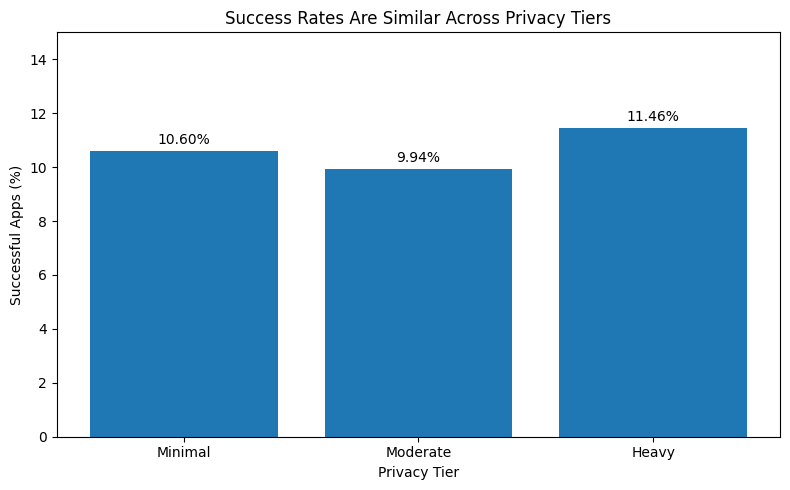

In [47]:
import matplotlib.pyplot as plt

tiers = ["Minimal", "Moderate", "Heavy"]
success_rates = [10.60, 9.94, 11.46]

plt.figure(figsize=(8, 5))

bars = plt.bar(tiers, success_rates)

plt.title("Success Rates Are Similar Across Privacy Tiers")
plt.xlabel("Privacy Tier")
plt.ylabel("Successful Apps (%)")
plt.ylim(0, 15)

for bar, rate in zip(bars, success_rates):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.25,
        f"{rate:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

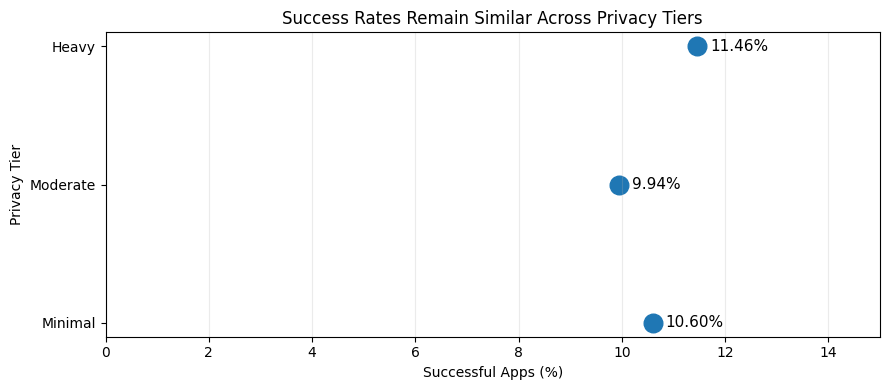

In [48]:
import matplotlib.pyplot as plt

tiers = ["Minimal", "Moderate", "Heavy"]
success_rates = [10.60, 9.94, 11.46]

plt.figure(figsize=(9, 4))

plt.scatter(
    success_rates,
    tiers,
    s=180
)

for rate, tier in zip(success_rates, tiers):
    plt.text(
        rate + 0.25,
        tier,
        f"{rate:.2f}%",
        va="center",
        fontsize=11
    )

plt.xlim(0, 15)

plt.title("Success Rates Remain Similar Across Privacy Tiers")
plt.xlabel("Successful Apps (%)")
plt.ylabel("Privacy Tier")

plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

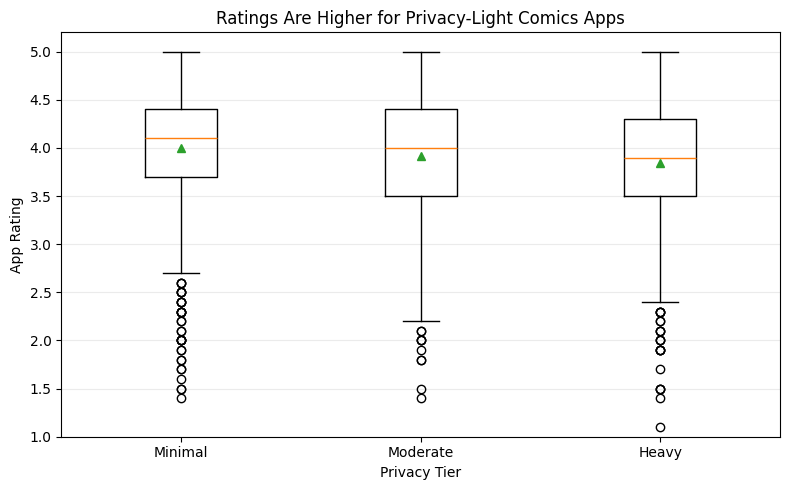

In [49]:
import matplotlib.pyplot as plt

rating_data = [
    comics_rated[
        comics_rated["privacy_tier"] == "Minimal"
    ]["rating"],

    comics_rated[
        comics_rated["privacy_tier"] == "Moderate"
    ]["rating"],

    comics_rated[
        comics_rated["privacy_tier"] == "Heavy"
    ]["rating"]
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    rating_data,
    tick_labels=["Minimal", "Moderate", "Heavy"],
    showmeans=True
)

plt.title("Ratings Are Higher for Privacy-Light Comics Apps")
plt.xlabel("Privacy Tier")
plt.ylabel("App Rating")
plt.ylim(1, 5.2)

plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

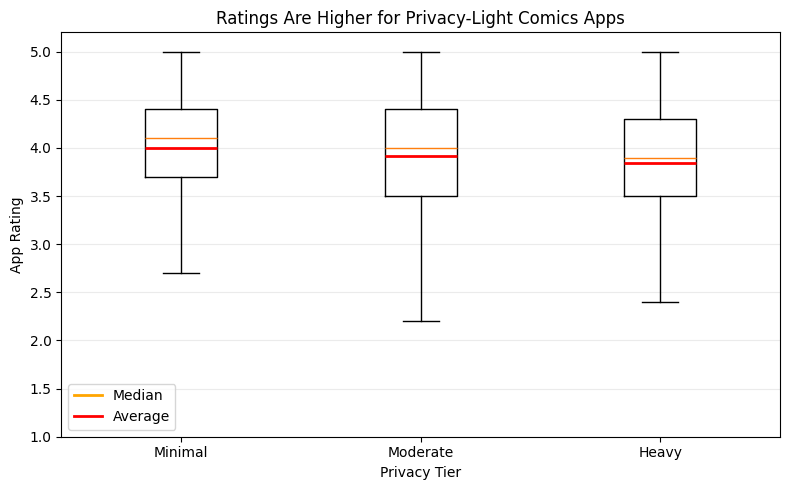

In [50]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

rating_data = [
    comics_rated[
        comics_rated["privacy_tier"] == "Minimal"
    ]["rating"],

    comics_rated[
        comics_rated["privacy_tier"] == "Moderate"
    ]["rating"],

    comics_rated[
        comics_rated["privacy_tier"] == "Heavy"
    ]["rating"]
]

plt.figure(figsize=(8, 5))

bp = plt.boxplot(
    rating_data,
    tick_labels=["Minimal", "Moderate", "Heavy"],
    showmeans=True,
    meanline=True,
    showfliers=False,
    meanprops=dict(
        color="red",
        linewidth=2,
        linestyle="-"
    )
)

plt.title("Ratings Are Higher for Privacy-Light Comics Apps")
plt.xlabel("Privacy Tier")
plt.ylabel("App Rating")
plt.ylim(1, 5.2)

plt.grid(axis="y", alpha=0.25)

# Legend
legend_items = [
    Line2D([0], [0], color="orange", linewidth=2, label="Median"),
    Line2D([0], [0], color="red", linewidth=2, label="Average")
]

plt.legend(
    handles=legend_items,
    loc="lower left",
    frameon=True
)

plt.tight_layout()
plt.show()

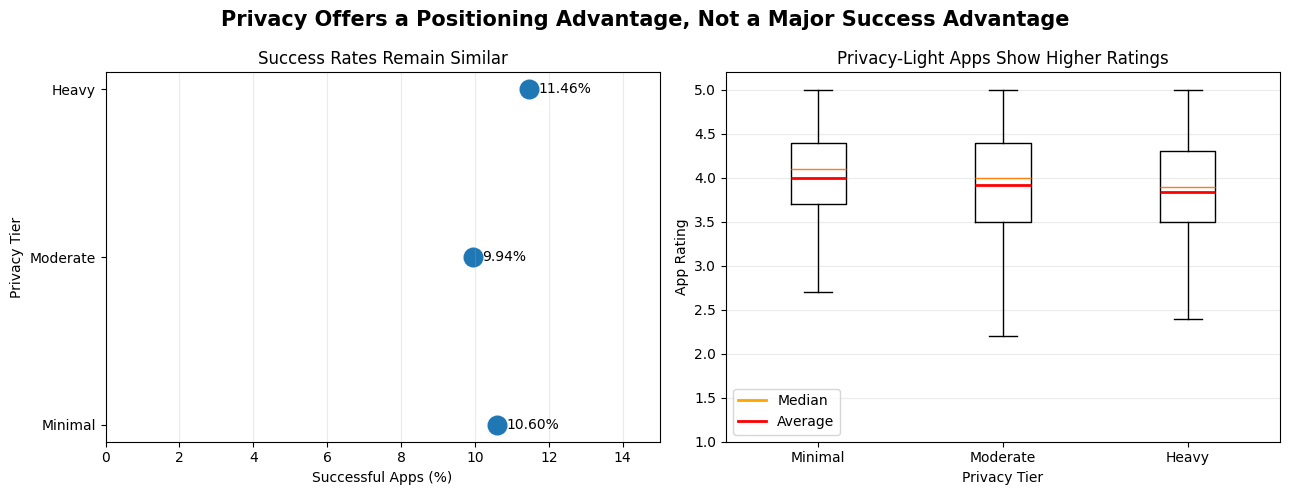

In [51]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

tiers = ["Minimal", "Moderate", "Heavy"]
success_rates = [10.60, 9.94, 11.46]

rating_data = [
    comics_rated[
        comics_rated["privacy_tier"] == "Minimal"
    ]["rating"],

    comics_rated[
        comics_rated["privacy_tier"] == "Moderate"
    ]["rating"],

    comics_rated[
        comics_rated["privacy_tier"] == "Heavy"
    ]["rating"]
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))


# ---------------------------
# LEFT: Success-rate dot plot
# ---------------------------

axes[0].scatter(
    success_rates,
    tiers,
    s=180
)

for rate, tier in zip(success_rates, tiers):
    axes[0].text(
        rate + 0.25,
        tier,
        f"{rate:.2f}%",
        va="center",
        fontsize=10
    )

axes[0].set_xlim(0, 15)

axes[0].set_title(
    "Success Rates Remain Similar"
)

axes[0].set_xlabel(
    "Successful Apps (%)"
)

axes[0].set_ylabel(
    "Privacy Tier"
)

axes[0].grid(
    axis="x",
    alpha=0.25
)


# ---------------------------
# RIGHT: Rating box plot
# ---------------------------

axes[1].boxplot(
    rating_data,
    tick_labels=tiers,
    showmeans=True,
    meanline=True,
    showfliers=False,
    meanprops=dict(
        color="red",
        linewidth=2,
        linestyle="-"
    )
)

axes[1].set_title(
    "Privacy-Light Apps Show Higher Ratings"
)

axes[1].set_xlabel(
    "Privacy Tier"
)

axes[1].set_ylabel(
    "App Rating"
)

axes[1].set_ylim(1, 5.2)

axes[1].grid(
    axis="y",
    alpha=0.25
)


# ---------------------------
# Rating legend
# ---------------------------

legend_items = [
    Line2D(
        [0], [0],
        color="orange",
        linewidth=2,
        label="Median"
    ),
    Line2D(
        [0], [0],
        color="red",
        linewidth=2,
        label="Average"
    )
]

axes[1].legend(
    handles=legend_items,
    loc="lower left"
)


# ---------------------------
# Overall title
# ---------------------------

fig.suptitle(
    "Privacy Offers a Positioning Advantage, Not a Major Success Advantage",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1697/3436971198.py:180: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.07, 1, 1])


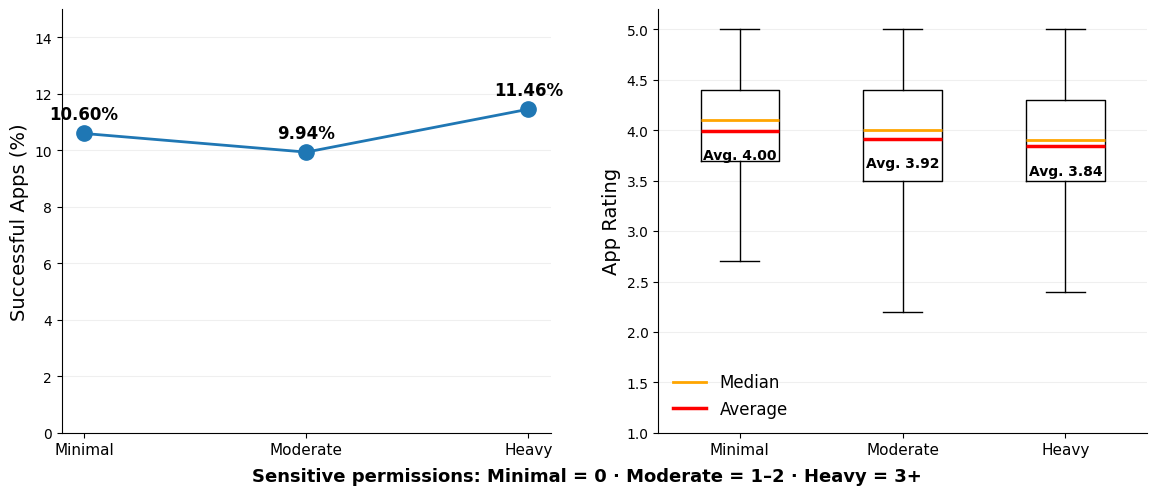

In [52]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

# ---------------------------
# Data
# ---------------------------

tiers = ["Minimal", "Moderate", "Heavy"]
x = np.arange(len(tiers))

success_rates = [10.60, 9.94, 11.46]
average_ratings = [4.00, 3.92, 3.84]

rating_data = [
    comics_rated[
        comics_rated["privacy_tier"] == "Minimal"
    ]["rating"],

    comics_rated[
        comics_rated["privacy_tier"] == "Moderate"
    ]["rating"],

    comics_rated[
        comics_rated["privacy_tier"] == "Heavy"
    ]["rating"]
]


# ---------------------------
# Figure
# ---------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    gridspec_kw={"wspace": 0.22}
)


# ==========================================================
# LEFT — Success rate
# ==========================================================

axes[0].plot(
    x,
    success_rates,
    marker="o",
    markersize=11,
    linewidth=2
)

for i, rate in enumerate(success_rates):
    axes[0].text(
        i,
        rate + 0.35,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

axes[0].set_xticks(x)
axes[0].set_xticklabels(tiers, fontsize=11)

axes[0].set_ylabel(
    "Successful Apps (%)",
    fontsize=14
)

axes[0].set_ylim(0, 15)

axes[0].grid(
    axis="y",
    alpha=0.20
)

axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)


# ==========================================================
# RIGHT — Rating distribution
# ==========================================================

bp = axes[1].boxplot(
    rating_data,
    positions=x,
    widths=0.48,
    tick_labels=tiers,
    showmeans=True,
    meanline=True,
    showfliers=False,
    meanprops=dict(
        color="red",
        linewidth=2.5,
        linestyle="-"
    ),
    medianprops=dict(
        color="orange",
        linewidth=2
    )
)

# Label average rating directly
for i, avg in enumerate(average_ratings):
    axes[1].text(
        i,
        avg - 0.18,
        f"Avg. {avg:.2f}",
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold"
    )

axes[1].set_ylabel(
    "App Rating",
    fontsize=14
)

axes[1].set_ylim(1, 5.2)

axes[1].tick_params(
    axis="x",
    labelsize=11
)

axes[1].grid(
    axis="y",
    alpha=0.20
)

axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)


# ---------------------------
# Legend
# ---------------------------

legend_items = [
    Line2D(
        [0], [0],
        color="orange",
        linewidth=2,
        label="Median"
    ),
    Line2D(
        [0], [0],
        color="red",
        linewidth=2.5,
        label="Average"
    )
]

axes[1].legend(
    handles=legend_items,
    loc="lower left",
    fontsize=12,
    frameon=False
)


# ---------------------------
# Tier definition / sample
# ---------------------------

fig.text(
    0.5,
    0.015,
    "Sensitive permissions: Minimal = 0 · Moderate = 1–2 · Heavy = 3+",
    ha="center",
    va="bottom",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

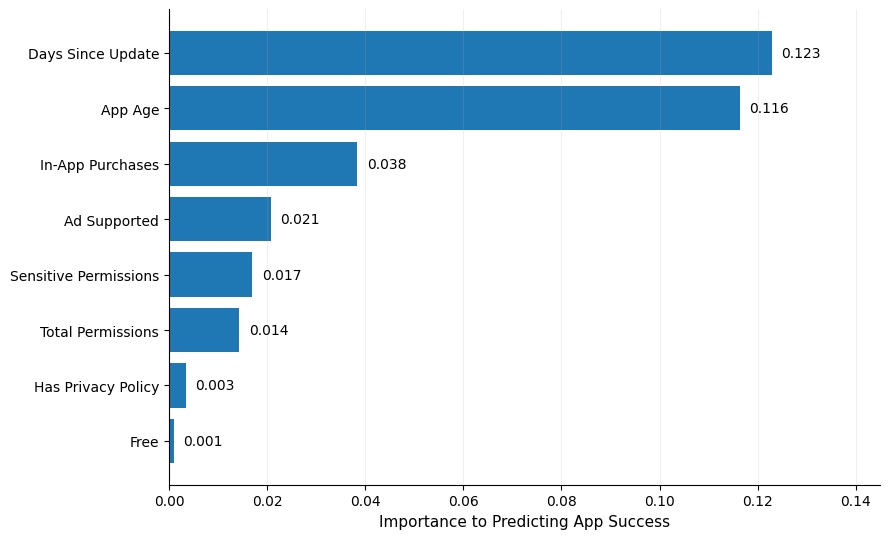

In [53]:
import matplotlib.pyplot as plt

# Use the permutation importance results
plot_data = permutation_df.sort_values(
    "importance",
    ascending=True
)

# Cleaner names for presentation
feature_labels = {
    "days_since_update": "Days Since Update",
    "app_age_years": "App Age",
    "in_app_purchases": "In-App Purchases",
    "ad_supported": "Ad Supported",
    "sensitive_permission_count": "Sensitive Permissions",
    "permission_count": "Total Permissions",
    "has_privacy_policy": "Has Privacy Policy",
    "free": "Free"
}

labels = [
    feature_labels[feature]
    for feature in plot_data["feature"]
]

plt.figure(figsize=(9, 5.5))

bars = plt.barh(
    labels,
    plot_data["importance"]
)


plt.xlabel(
    "Importance to Predicting App Success",
    fontsize=11
)

plt.ylabel("")

plt.grid(
    axis="x",
    alpha=0.20
)

# Add values to the end of each bar
for bar, value in zip(bars, plot_data["importance"]):
    plt.text(
        value + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=10
    )

plt.xlim(
    0,
    plot_data["importance"].max() * 1.18
)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [54]:
monetization_summary = (
    comics["monetization_model"]
    .value_counts()
    .to_frame("apps")
)

monetization_summary["percent"] = (
    monetization_summary["apps"]
    / len(comics)
    * 100
).round(1)

monetization_summary

,apps,percent
monetization_model,,
Ad-supported,1783,65.1
Free (no monetization),438,16.0
Freemium (Ads + IAP),355,13.0
Freemium (IAP only),117,4.3
Paid,45,1.6


In [55]:
successful_comics = comics[
    comics["is_successful"] == True
].copy()

successful_monetization = (
    successful_comics["monetization_model"]
    .value_counts()
    .to_frame("successful_apps")
)

successful_monetization["percent_of_successful"] = (
    successful_monetization["successful_apps"]
    / len(successful_comics)
    * 100
).round(1)

print("Successful Comics apps:", len(successful_comics))
print()

successful_monetization

Successful Comics apps: 290



,successful_apps,percent_of_successful
monetization_model,,
Ad-supported,179,61.7
Freemium (Ads + IAP),78,26.9
Freemium (IAP only),20,6.9
Free (no monetization),13,4.5
Paid,0,0.0


In [56]:
monetization_success = (
    comics
    .groupby("monetization_model", observed=True)
    .agg(
        apps=("is_successful", "size"),
        successful_apps=("is_successful", "sum"),
        success_rate=("is_successful", "mean")
    )
)

monetization_success["success_rate"] = (
    monetization_success["success_rate"] * 100
).round(2)

monetization_success = monetization_success.sort_values(
    "success_rate",
    ascending=False
)

monetization_success

,apps,successful_apps,success_rate
monetization_model,,,
Freemium (Ads + IAP),355,78,21.97
Freemium (IAP only),117,20,17.09
Ad-supported,1783,179,10.04
Free (no monetization),438,13,2.97
Paid,45,0,0.00


In [57]:
monetization_performance = (
    comics
    .groupby("monetization_model", observed=True)
    .agg(
        apps=("app_id", "size"),
        rated_apps=("rating", "count"),
        median_rating=("rating", "median"),
        average_rating=("rating", "mean"),
        median_minimum_installs=("minimum_installs", "median")
    )
    .round({
        "median_rating": 2,
        "average_rating": 2,
        "median_minimum_installs": 0
    })
)

# Add the success rates we already calculated
monetization_performance = monetization_performance.join(
    monetization_success[["success_rate"]]
)

monetization_performance = monetization_performance.sort_values(
    "success_rate",
    ascending=False
)

monetization_performance

,apps,rated_apps,median_rating,average_rating,median_minimum_installs,success_rate
monetization_model,,,,,,
Freemium (Ads + IAP),355,309,4.0,3.93,50000.0,21.97
Freemium (IAP only),117,97,4.0,3.85,10000.0,17.09
Ad-supported,1783,1293,4.0,3.91,5000.0,10.04
Free (no monetization),438,251,4.1,3.96,500.0,2.97
Paid,45,39,4.5,4.30,1000.0,0.00


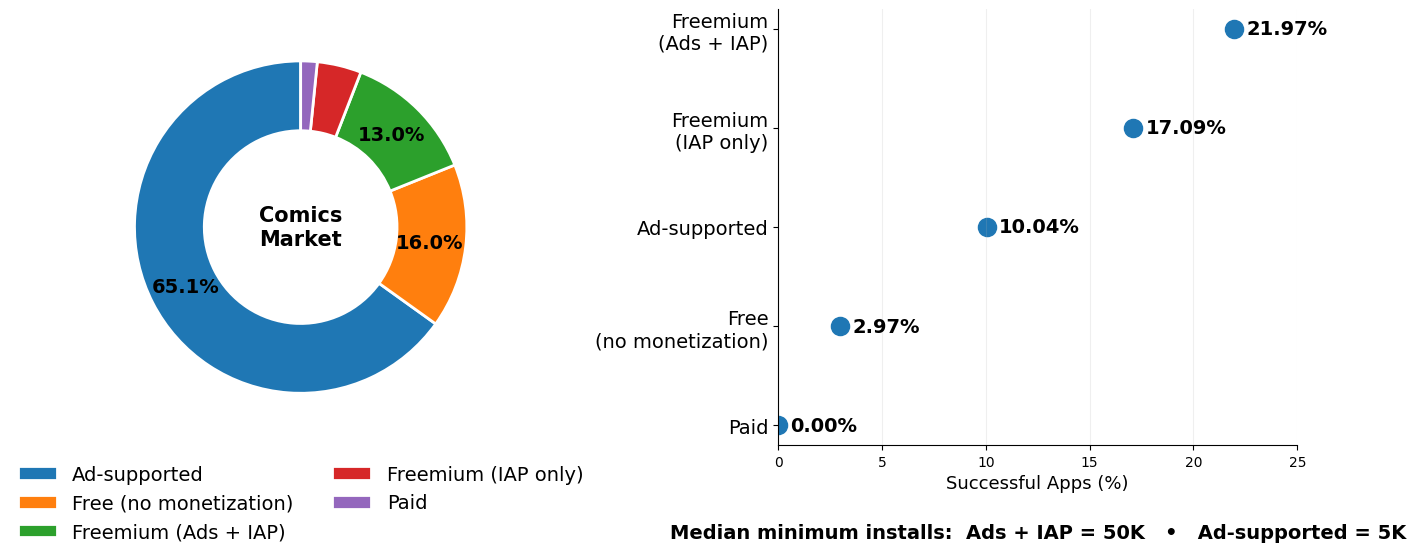

In [58]:
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------
# Data
# ---------------------------

models = [
    "Ad-supported",
    "Free (no monetization)",
    "Freemium (Ads + IAP)",
    "Freemium (IAP only)",
    "Paid"
]

market_share = [65.1, 16.0, 13.0, 4.3, 1.6]

success_models = [
    "Freemium\n(Ads + IAP)",
    "Freemium\n(IAP only)",
    "Ad-supported",
    "Free\n(no monetization)",
    "Paid"
]

success_rates = [21.97, 17.09, 10.04, 2.97, 0.00]


# ---------------------------
# Figure
# ---------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    gridspec_kw={"width_ratios": [1, 1.25]}
)


# ==========================================================
# LEFT — Market distribution
# ==========================================================

wedges, texts, autotexts = axes[0].pie(
    market_share,
    startangle=90,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 5 else "",
    pctdistance=0.78,
    wedgeprops=dict(
        width=0.42,
        edgecolor="white",
        linewidth=2
    )
)

# Make percentages easier to read
for text in autotexts:
    text.set_fontsize(14)
    text.set_fontweight("bold")

# Center text
axes[0].text(
    0,
    0,
    "Comics\nMarket",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold"
)

# Clean legend instead of labels around donut
axes[0].legend(
    wedges,
    models,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.03),
    frameon=False,
    fontsize=14,
    ncol=2
)

axes[0].set_aspect("equal")


# ==========================================================
# RIGHT — Success rate
# ==========================================================

y = np.arange(len(success_models))

axes[1].scatter(
    success_rates,
    y,
    s=170
)

for i, rate in enumerate(success_rates):
    axes[1].text(
        rate + 0.6,
        i,
        f"{rate:.2f}%",
        va="center",
        fontsize=14,
        fontweight="bold"
    )

axes[1].set_yticks(y)
axes[1].set_yticklabels(success_models, fontsize=14)

axes[1].invert_yaxis()

axes[1].set_xlim(0, 25)

axes[1].set_xlabel(
    "Successful Apps (%)",
    fontsize=13
)

axes[1].grid(
    axis="x",
    alpha=0.20
)

axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

axes[1].text(
    0.5,
    -0.18,
    "Median minimum installs:  Ads + IAP = 50K   •   Ad-supported = 5K",
    transform=axes[1].transAxes,
    ha="center",
    va="top",
    fontsize=14,
    fontweight="bold"
)


plt.tight_layout()
plt.subplots_adjust(bottom=0.18)
plt.show()

In [59]:
comics_examples = df[
    df["category"] == "Comics"
][[
    "app_name",
    "developer_id",
    "rating",
    "rating_count",
    "minimum_installs"
]].copy()

print("Number of Comics apps:", len(comics_examples))

comics_examples.sort_values(
    "minimum_installs",
    ascending=False
).head(30)

Number of Comics apps: 2862


,app_name,developer_id,rating,rating_count,minimum_installs
1158815,WEBTOON,WEBTOON ENTERTAINMENT,4.6,1746185,50000000
2205106,"MangaToon-Good comics, Great stories",MangaToon,4.4,488830,10000000
1971941,Comics,comiXology,3.8,59694,10000000
344921,다음웹툰 - DAUM WEBTOON,Kakao Corp.,3.4,31048,10000000
381014,Temple Princess Lost Oz Run,App Mag,4.1,20947,10000000
319746,Marvel Comics,Marvel Comics,3.9,55696,10000000
2001352,Talking James Squirrel - Virtual Pet,Kaufcom Games Apps Widgets,4.3,62222,10000000
1894999,네이버 웹툰 - Naver Webtoon,NAVER WEBTOON,3.9,197768,10000000
210704,Draw Cartoons 2: Skeletal Animation Studio,Zalivka Mobile Cartoons,4.5,320001,10000000
1873417,IGI Sniper 2019: US Army Commando Mission,Game Nitro Studio,4.1,11997,5000000
